# EMQA_L2_mape_fail

**Why percentage errors fail near zero and negative prices**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_mape_fail/EMQA_L2_mape_fail.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Panels of price, load and wind + solar

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "load", "wind_onshore", "solar"])
LM, _ = day_matrix(GH["load"].dropna())
RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
LM, RM = LM.reindex(CAL), RM.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any(), "panel has gaps"
L_, R_ = LM.values.astype(float), RM.values.astype(float)
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## Forecasts

LEAR (LASSO-estimated autoregression, 247 candidate regressors, $\lambda$ by AIC) is re-estimated every day for each hour and for the windows 364, 546 and 728 days; AW-LEAR is the average across the three windows. This takes about 2.5 s per day and window, so the forecasts computed by `lectures/L2/analysis_L2.py` are loaded from the file saved next to this notebook. Set `RUN_ALL = True` to recompute them with the code below.

In [5]:
RUN_ALL = False   # True: recompute the forecasts from the data (LEAR roughly 45 min on one core; joblib uses all cores)

QL = REPO + "Quantlets/L2/EMQA_L2_mape_fail/"          # saved results of this Quantlet


def load_npz(path):
    if path.startswith("http"):
        import io
        import urllib.request
        return np.load(io.BytesIO(urllib.request.urlopen(path).read()))
    return np.load(path)


def load_csv(name, days):
    S = pd.read_csv(QL + name, parse_dates=["date"], float_precision="round_trip")
    assert (pd.DatetimeIndex(S["date"].drop_duplicates()) == days).all()
    return S


from scipy import stats


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)                   # price lags; lags of load and wind+solar (days)
LEAR_W = (364, 546, 728)


def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


if RUN_ALL:
    from joblib import Parallel, delayed
    _r = Parallel(n_jobs=-1)(delayed(lear_day)(P_, L_, R_, i, T) for T in LEAR_W for i in TI_ROWS)
    _n = len(TI_ROWS)
    LEAR = {T: np.array([r[0] for r in _r[k * _n:(k + 1) * _n]]) for k, T in enumerate(LEAR_W)}
else:
    S = load_csv("forecasts_test.csv", TDAYS)
    LEAR = {T: S[f"lear{T}"].values.reshape(-1, 24) for T in LEAR_W}
AW_LEAR = np.mean([LEAR[T] for T in LEAR_W], 0)
print("AW-LEAR MAE on the test year: %.2f EUR/MWh" % np.mean(np.abs(A - AW_LEAR)))

AW-LEAR MAE on the test year: 22.53 EUR/MWh


## Absolute percentage errors

In [6]:
_ape = np.abs(A - AW_LEAR) / np.abs(A)
_ape[~np.isfinite(_ape)] = np.nan      # price exactly 0: undefined
small = np.abs(A) < 5
MAPE = np.nanmean(_ape) * 100
MAPE_EXCL5 = np.nanmean(_ape[~small]) * 100
SHARE_SMALL = np.nansum(_ape[small]) / np.nansum(_ape) * 100
N_SMALL = int(small.sum())

## The chart

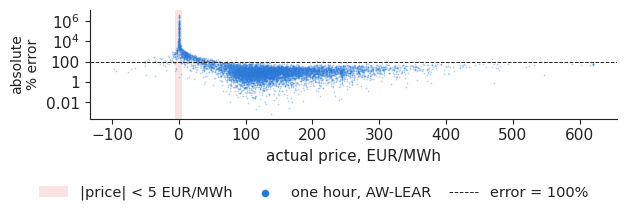

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 2.2))
x_, y_ = A.ravel(), (_ape.ravel() * 100)
ok = np.isfinite(y_) & (y_ > 0)
ax.axvspan(-5, 5, color=PAL["c8"], alpha=0.15, lw=0, label="|price| < 5 EUR/MWh")
ax.scatter(np.clip(x_[ok], -120, 620), y_[ok], s=1.5, color=PAL["RO"], alpha=0.35, lw=0, label="one hour, AW-LEAR")
ax.axhline(100, color="#222222", lw=0.7, ls="--", label="error = 100%")
ax.set_yscale("log")
ax.set_yticks([1e-2, 1, 1e2, 1e4, 1e6])
ax.set_yticklabels(["0.01", "1", "100", "10$^4$", "10$^6$"])
ax.set_xlabel("actual price, EUR/MWh")
ax.set_ylabel("absolute\n% error", fontsize=10)
legend_bottom(fig, ncol=3)
for h_ in fig.legends[-1].legend_handles:
    if hasattr(h_, 'set_sizes'):
        h_.set_sizes([30]); h_.set_alpha(1)
fig.tight_layout(rect=(0, 0.15, 1, 1))
plt.savefig('mape_fail.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [8]:
print("Numbers on the slide")
print(f'  MAPE of AW-LEAR, %: {MAPE:.1f}')
print(f'  MAPE without |price| < 5, %: {MAPE_EXCL5:.1f}')
print(f'  hours with |price| < 5 EUR/MWh: {N_SMALL:d}')
print(f'  share of the MAPE from these hours, %: {SHARE_SMALL:.1f}')

Numbers on the slide
  MAPE of AW-LEAR, %: 5777.7
  MAPE without |price| < 5, %: 32.4
  hours with |price| < 5 EUR/MWh: 387
  share of the MAPE from these hours, %: 99.5
